# 01 – EDA and degradation analysis (C-MAPSS FD001)
Sensor trends vs. cycles-to-failure, engine life distribution, and sensor–RUL correlation. Plots are saved to `docs/images/`.

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data.load import clean, SENSOR_COLS

IMG = Path("../docs/images"); IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
train, test, rul, dropped = clean("FD001", Path("../data/raw"))
sensors = [c for c in SENSOR_COLS if c in train.columns]
train["rul"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]
print(train.shape, len(sensors), "informative sensors")

(20631, 20) 15 informative sensors


## Engine life-length distribution

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


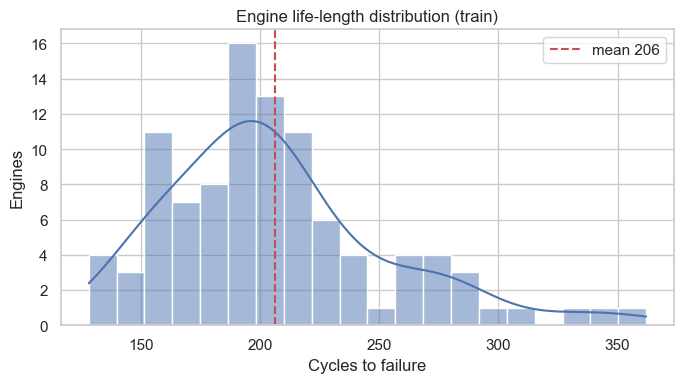

In [2]:
life = train.groupby("engine_id")["cycle"].max()
print(life.describe())
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(life, bins=20, kde=True, ax=ax)
ax.axvline(life.mean(), color="r", ls="--", label=f"mean {life.mean():.0f}")
ax.set(xlabel="Cycles to failure", ylabel="Engines", title="Engine life-length distribution (train)")
ax.legend(); fig.tight_layout(); fig.savefig(IMG / "life_distribution.png", dpi=150)

## Sensor trends against cycles-to-failure
Sensors vs. RUL for a sample of engines (x-axis reversed: failure on the right).

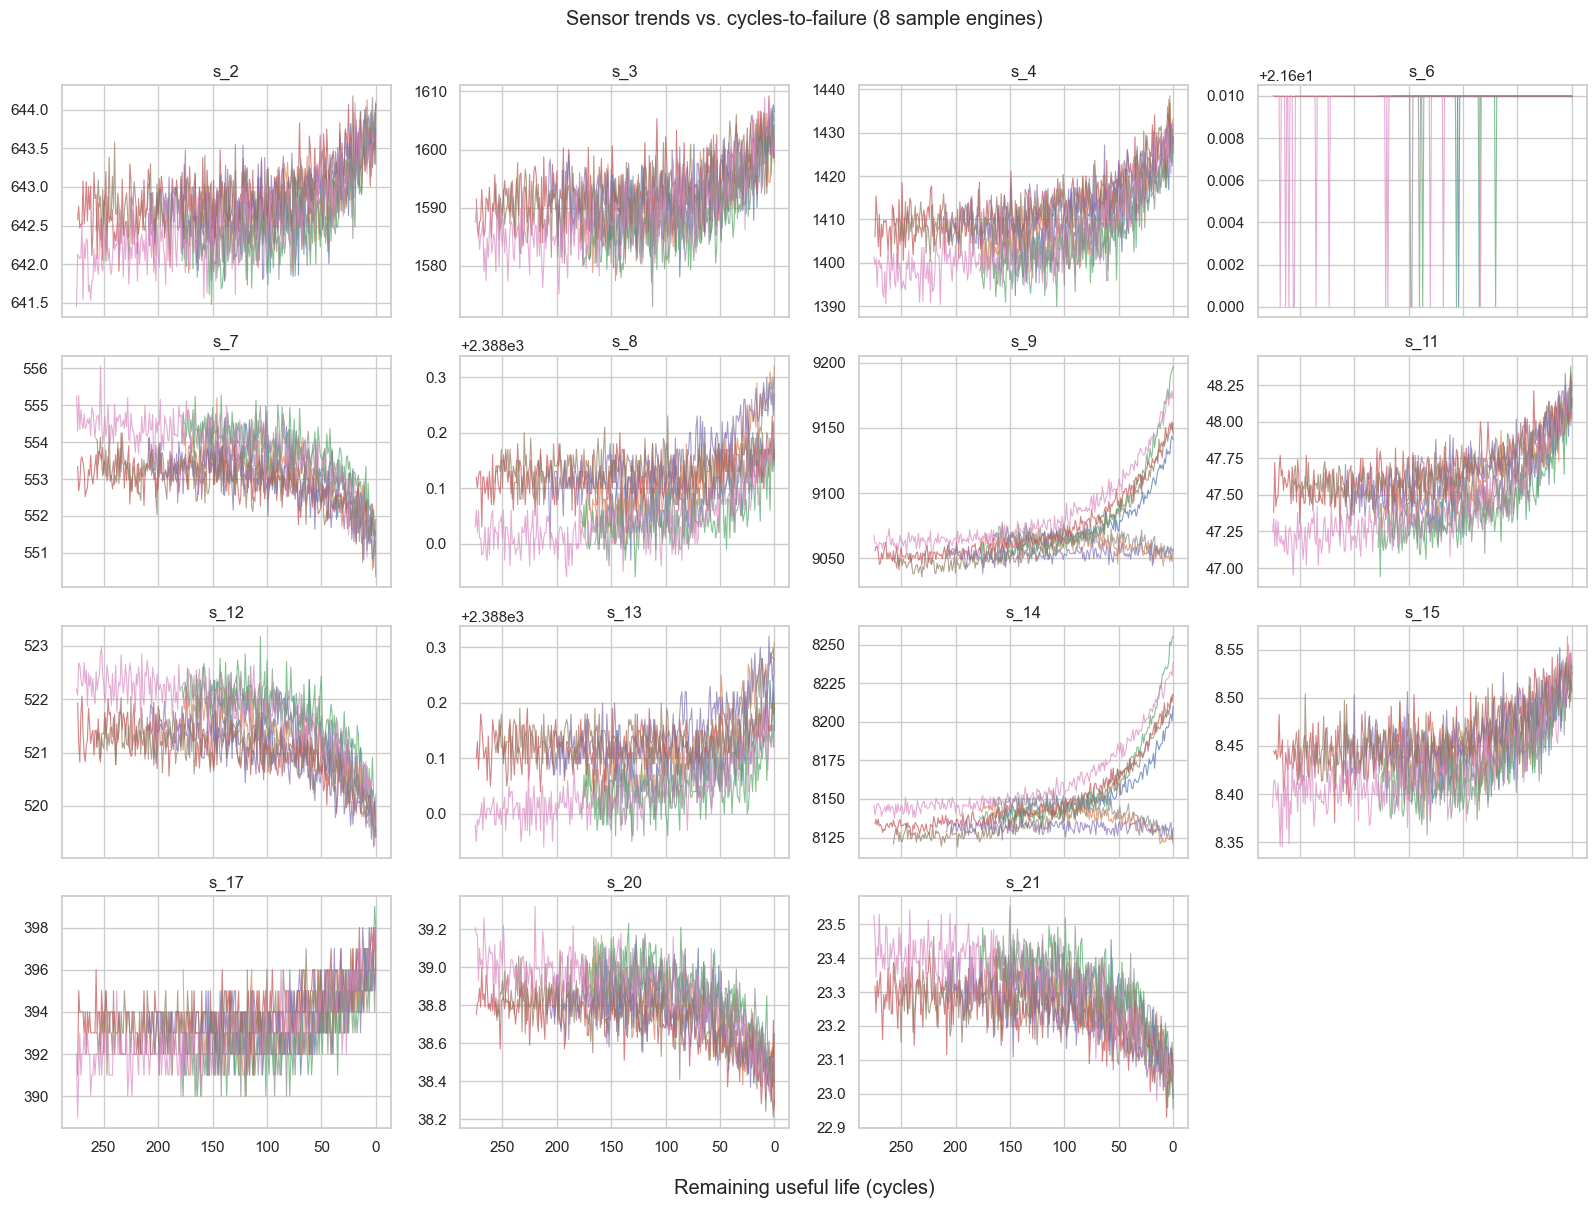

In [3]:
sample = train["engine_id"].drop_duplicates().sample(8, random_state=0)
n = len(sensors); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=True)
for ax, s in zip(axes.ravel(), sensors):
    for e in sample:
        d = train[train.engine_id == e]
        ax.plot(d["rul"], d[s], lw=0.8, alpha=0.7)
    ax.set_title(s); ax.invert_xaxis()
for ax in axes.ravel()[n:]: ax.axis("off")
fig.supxlabel("Remaining useful life (cycles)")
fig.suptitle("Sensor trends vs. cycles-to-failure (8 sample engines)", y=1.00)
fig.tight_layout(); fig.savefig(IMG / "sensor_trends.png", dpi=130)

## Sensor–RUL correlation

s_11   -0.696228
s_4    -0.678948
s_12    0.671983
s_7     0.657223
s_15   -0.642667
s_21    0.635662
s_20    0.629428
s_2    -0.606484
s_17   -0.606154
s_3    -0.584520
s_8    -0.563968
s_13   -0.562569
s_9    -0.390102
s_14   -0.306769
s_6    -0.128348
Name: rul, dtype: float64

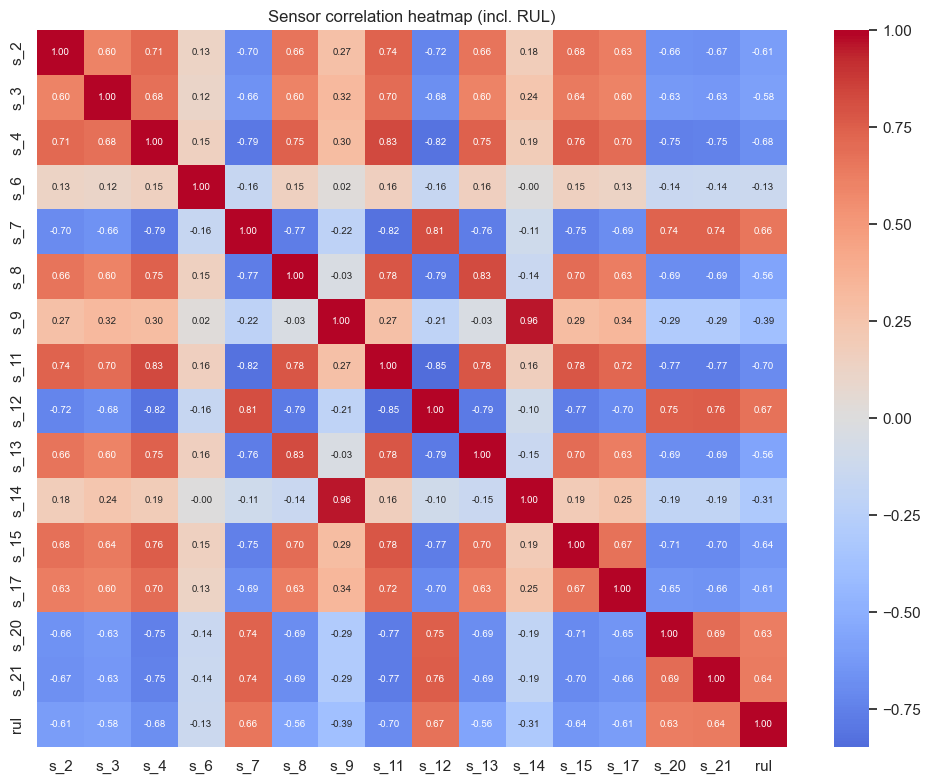

In [4]:
corr = train[sensors + ["rul"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Sensor correlation heatmap (incl. RUL)")
fig.tight_layout(); fig.savefig(IMG / "correlation_heatmap.png", dpi=150)
rul_corr = corr["rul"].drop("rul").sort_values(key=abs, ascending=False)
rul_corr

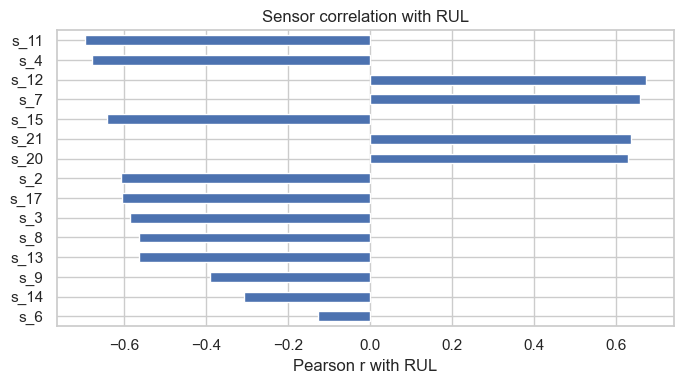

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
rul_corr.plot.barh(ax=ax); ax.invert_yaxis()
ax.set(xlabel="Pearson r with RUL", title="Sensor correlation with RUL")
fig.tight_layout(); fig.savefig(IMG / "rul_correlation_bar.png", dpi=150)

## Findings
- Engines fail after 128-362 cycles (mean 206, median 199): life is right-skewed, so engines are not interchangeable and RUL must be estimated per engine.
- 15 sensors remain after dropping constants. The strongest RUL correlations are s_11 (-0.70), s_4 (-0.68), s_12 (+0.67), s_7 (+0.66), s_15 (-0.64), s_21 (+0.64) and s_20 (+0.63).
- Sensors are flat and noisy early in life, then drift (s_9 and s_14 sharply) over the last ~50-100 cycles. Healthy baselines differ per engine, which motivates per-engine normalization and baseline-delta features.
- s_6 is nearly binary (0.00/0.01) and weakly correlated (-0.13); s_14 and s_9 are bimodal across engines (some rise, some stay flat).
- Because degradation only becomes visible late, early-life RUL is not predictable; Phase 3 uses a **capped RUL (~125)**.